---
<a href="https://colab.research.google.com/github/hc2x/civl7740/blob/main/tutorial-eof-sst.ipynb" target="_blank">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/>
</a>

# Instruction for Google Colab environment
- In order to make edits to this notebook, you should press File > "Save a Copy in Drive". This will ensure that any edits will be on your local copy, and they will not affect the notebook shared with everyone else.
- Click "Connect" on the top-right corner. Once you see RAM and Disk, you are ready to run the codes!
---

# EOF Analysis of Tropical Pacific Sea Surface Temperature

Prepared by Donghoon Lee (Donghoon.Lee@umanitoba.ca)

In the previous tutorial (`tutorial-eof-analysis.ipynb`) we decomposed a **2-variable** data set (minimum temperature at Ithaca and Canandaigua) into eigenvectors and principal components. Here we apply exactly the same mathematics to a **real gridded field**: monthly SST over the tropical Pacific, where every ocean grid cell is one variable (a few thousand variables).

In this tutorial, we will
1. Download NOAA ERSST v5 and compute monthly SST anomalies for the tropical Pacific
2. **Part A – EOF "by hand"**: build the data matrix, the covariance matrix, and solve the eigenvalue problem ourselves
3. Compute the **correlation between a PC and SST at every grid cell** with linear algebra (no loops)
4. **Part B – EOF with a package**: repeat the analysis with the `eofs` package and confirm we get the same answer
5. Interpret EOF-1 / PC-1 as ENSO and compare PC-1 with the Niño 3.4 index

### Recap: from a 2-variable example to a gridded field

| | Previous tutorial | This tutorial |
|---|---|---|
| Observations ($n$) | 31 days | ~900 months (1950–present) |
| Variables ($p$) | 2 stations | ~2,000+ ocean grid cells |
| Data matrix $\mathbf{X}$ | $31 \times 2$ | $n \times p$ |
| Covariance $\mathbf{\Sigma} = \frac{1}{n-1}\mathbf{X}^T\mathbf{X}$ | $2 \times 2$ | $p \times p$ |
| Eigenvectors $\mathbf{E}$ (EOFs) | 2 arrows in a scatter plot | spatial **maps** |
| PCs $\mathbf{T} = \mathbf{X}\mathbf{E}$ | 31-day time series | monthly **time series** |

The only new ingredients are (1) reshaping a 3-D array `(time, lat, lon)` into a 2-D matrix `(time, space)` and back, (2) removing land points, and (3) **area weighting** (grid cells shrink toward the poles).

In [1]:
!pip install -q cartopy eofs
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy import signal
from scipy.linalg import eigh

# Download SST data

Same data set as in `tutorial-sst-nino34.ipynb`: [NOAA Extended Reconstructed SST V5](https://psl.noaa.gov/data/gridded/data.noaa.ersst.v5.html) (2° × 2°, monthly, 1854–present). `-nc` skips the download if the file already exists.

In [2]:
!wget -nc ftp://ftp.cdc.noaa.gov/Datasets/noaa.ersst.v5/sst.mnmean.nc
# If the FTP server does not respond, use HTTPS instead:
# !wget -nc https://downloads.psl.noaa.gov/Datasets/noaa.ersst.v5/sst.mnmean.nc
!ls -la

File ‘sst.mnmean.nc’ already there; not retrieving.
total 40390744
drwxr-xr-x@   3 dlee  staff          96 Jan 12  2026 $RECYCLE.BIN
drwx------@ 802 dlee  staff       25664 Nov  4 22:58 .
drwxr-x---+  82 dlee  staff        2624 Nov  4 22:18 ..
-rw-r--r--@   1 dlee  staff      126980 Nov  4 22:52 .DS_Store
-rw-r--r--    1 dlee  staff           0 Jan 21  2024 .localized
-rw-r--r--@   1 dlee  staff       19190 May 13 22:30 01_data_overview.ipynb
-rw-r--r--@   1 dlee  staff    10671348 Jan  7  2023 1-s2.0-S0013935122024823-main.pdf
-rw-r--r--@   1 dlee  staff      520266 Oct 15  2024 1-s2.0-S0022169409007653-main.pdf
-rw-r--r--@   1 dlee  staff     4485369 Mar  6  2025 1-s2.0-S0034425715001637-main.pdf
-rw-r--r--@   1 dlee  staff     1640741 Jan 21  2023 1-s2.0-S0048969719331390-main.pdf
-rw-r--r--@   1 dlee  staff     4317748 May 11  2021 1-s2.0-S0048969721024372-main.pdf
-rw-r--r--@   1 dlee  staff     2567561 Nov  9  2025 1-s2.0-S0048969722050550-main.pdf
-rw-r--r--@   1 dlee  staff    

In [3]:
ds = xr.open_dataset('sst.mnmean.nc')
sst = ds['sst']
print(sst)
print('----------'*10)
print('First month:', sst.time.values[0], ' Last month:', sst.time.values[-1])

<xarray.DataArray 'sst' (time: 2074, lat: 89, lon: 180)> Size: 133MB
[33225480 values with dtype=float32]
Coordinates:
  * lat      (lat) float32 356B 88.0 86.0 84.0 82.0 ... -82.0 -84.0 -86.0 -88.0
  * lon      (lon) float32 720B 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
  * time     (time) datetime64[ns] 17kB 1854-01-01 1854-02-01 ... 2026-10-01
Attributes:
    long_name:     Monthly Means of Sea Surface Temperature
    units:         degC
    var_desc:      Sea Surface Temperature
    level_desc:    Surface
    statistic:     Mean
    dataset:       NOAA Extended Reconstructed SST V5
    parent_stat:   Individual Values
    actual_range:  [-1.8     42.32636]
    valid_range:   [-1.8 45. ]
----------------------------------------------------------------------------------------------------
First month: 1854-01-01T00:00:00.000000000  Last month: 2026-10-01T00:00:00.000000000


## Analysis settings

- **Domain**: tropical Pacific, 30°S–30°N, 120°E–70°W (ERSST longitude runs 0–360°, so 70°W = 290°E; latitude is stored north → south).
- **Period**: 1950–latest month (pre-1950 data are sparse and heavily infilled).
- **Climatology** (for anomalies): 1981–2010, the same base period used for the Niño 3.4 index.
- **Detrending**: removes the long-term warming trend at every grid cell. Without it, the trend can show up as one of the leading EOFs and mix with ENSO. Try `DETREND = False` later and compare.

In [4]:
LAT_N, LAT_S = 30, -30          # 30°N – 30°S
LON_W, LON_E = 120, 290         # 120°E – 70°W
START, END = '1950-01-01', None # None = latest available month
CLIM = ('1981-01-01', '2010-12-31')
DETREND = True
NMODES = 4                      # number of EOFs/PCs to show

sst_tp = sst.sel(lat=slice(LAT_N, LAT_S), lon=slice(LON_W, LON_E), time=slice(START, END))
print(sst_tp.dims, sst_tp.shape)

('time', 'lat', 'lon') (922, 31, 86)


A helper for map panels (used for every map below).

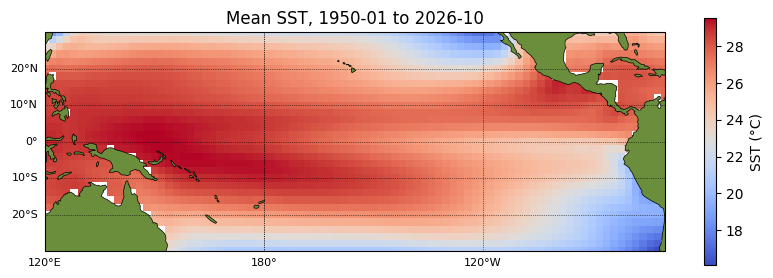

In [5]:
MAP_PROJ = ccrs.PlateCarree(central_longitude=180)   # keeps the Pacific in one piece
DATA_CRS = ccrs.PlateCarree()

def decorate_map(ax):
    ax.add_feature(cfeature.LAND, facecolor='#6b8e3d', zorder=2)
    ax.coastlines(linewidth=0.5, zorder=3)
    ax.set_extent([LON_W, LON_E, LAT_S, LAT_N], crs=DATA_CRS)
    gl = ax.gridlines(draw_labels=True, linestyle=':', color='k', linewidth=0.5)
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = gl.ylabel_style = {'size': 8}

fig, ax = plt.subplots(figsize=(10, 4), subplot_kw={'projection': MAP_PROJ})
sst_tp.mean('time').plot(ax=ax, transform=DATA_CRS, cmap='coolwarm', cbar_kwargs={'label': 'SST (°C)', 'shrink': 0.8})
decorate_map(ax)
ax.set_title(f'Mean SST, {str(sst_tp.time.values[0])[:7]} to {str(sst_tp.time.values[-1])[:7]}')
plt.show()

# Step 1. SST anomalies

EOF analysis looks for patterns of **variability**, so we must remove what does not vary from year to year:

1. **Seasonal cycle**: subtract the 1981–2010 mean of each calendar month (otherwise EOF-1 is simply "summer vs. winter").
2. **Linear trend** (optional): subtract a straight-line fit at each grid cell.
3. **Time mean**: EOFs are defined on mean-centered data ($\mathbf{X}$ in the previous tutorial was "mean-centered"). Detrending already removes the mean; we center again explicitly in Step 3 to be safe.

In [6]:
# 1) Remove the monthly climatology
clim = sst_tp.sel(time=slice(*CLIM)).groupby('time.month').mean('time')
anom = (sst_tp.groupby('time.month') - clim).drop_vars('month')

# Ocean mask: grid cells with valid data at every time step
ocean = anom.notnull().all('time')

# 2) Remove the linear trend (signal.detrend cannot handle NaN, so fill land with 0 and re-mask)
if DETREND:
    anom = anom.copy(data=signal.detrend(anom.fillna(0).values, axis=0)).where(ocean)

anom.name = 'sst_anom'
print(anom.shape, ' ocean cells:', int(ocean.sum()), ' land/missing cells:', int((~ocean).sum()))

(922, 31, 86)  ocean cells: 2418  land/missing cells: 248


Let's look at the anomaly during the strongest El Niño events of the record. EOF analysis will try to find this kind of pattern **automatically**, without us telling it where ENSO is.

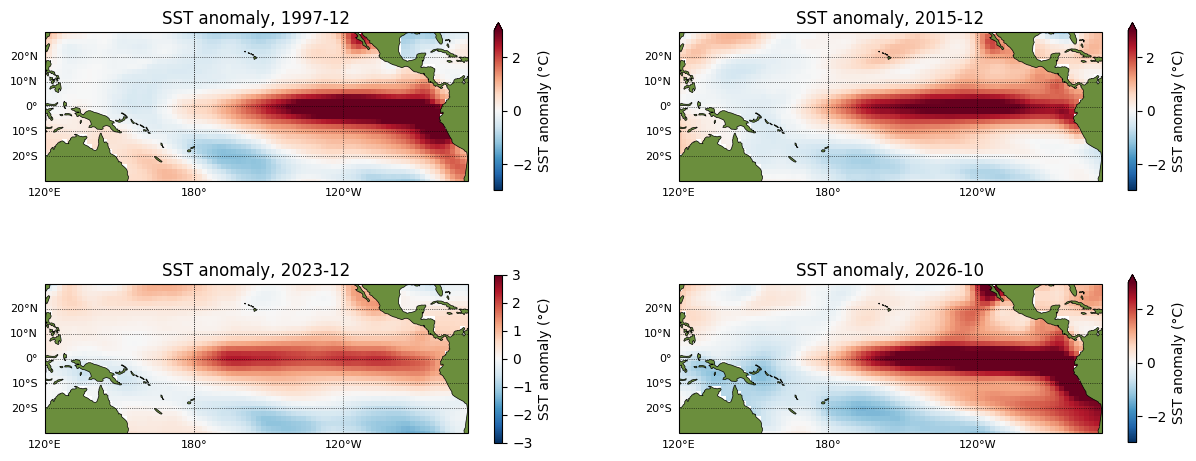

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(15, 6), subplot_kw={'projection': MAP_PROJ})
for ax, month in zip(axes.flat, ['1997-12', '2015-12', '2023-12', '2026-10']):
    anom.sel(time=month).squeeze().plot(ax=ax, transform=DATA_CRS, cmap='RdBu_r', vmin=-3, vmax=3,
                                        cbar_kwargs={'label': 'SST anomaly (°C)', 'shrink': 0.8})
    decorate_map(ax)
    ax.set_title(f'SST anomaly, {month}')
plt.show()

# Step 2. Area weighting

On a regular lat–lon grid, a 2°×2° cell gets narrower toward the poles: its north–south height ($R\,\Delta\phi$) is the same everywhere, but its east–west width ($R\cos\phi\,\Delta\lambda$) shrinks with latitude, so its **area is proportional to $\cos\phi$**. A cell at 30°N covers only $\cos(30°) \approx 0.87$ of the area of a cell at the equator.

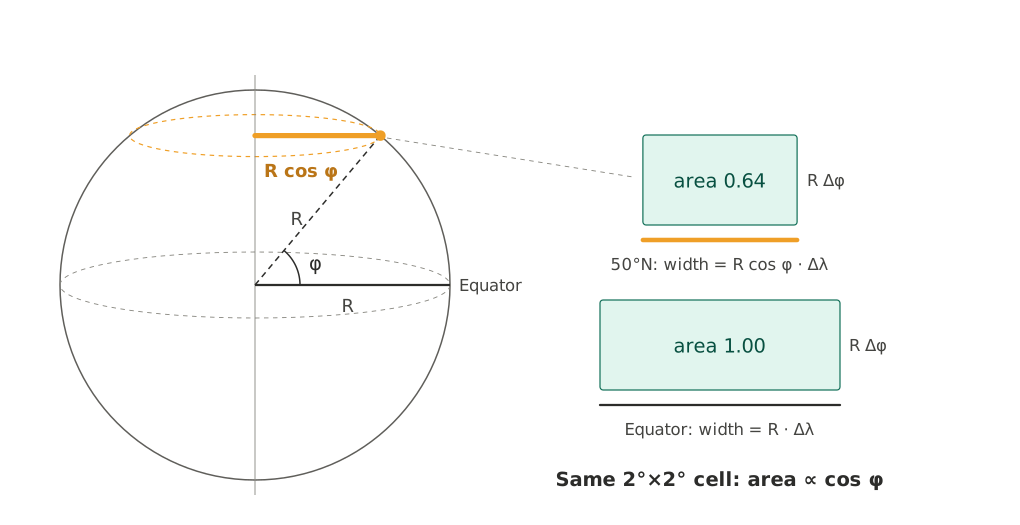

Without weighting, high-latitude cells are over-represented in the covariance matrix. The standard fix is to multiply each anomaly by $\sqrt{\cos\phi}$ **before** the decomposition. Because variance is the square of the data, this weights each cell's variance by $\cos\phi$, i.e., by its area:

$$
\tilde{x}_{t,j} = x_{t,j}\,\sqrt{\cos\phi_j}
$$

(In the tropics the effect is small, but if you extend the domain toward the poles it matters a lot.)

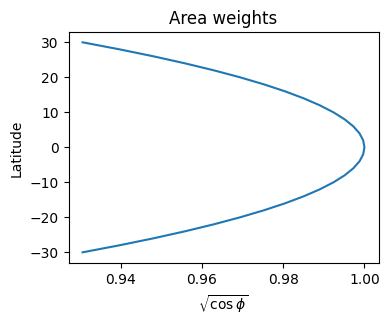

In [8]:
wgts = np.sqrt(np.cos(np.deg2rad(anom.lat)))   # 1-D weights along latitude
anom_w = anom * wgts                            # xarray broadcasts over (time, lat, lon)

plt.figure(figsize=(4, 3))
plt.plot(wgts, anom.lat)
plt.xlabel(r'$\sqrt{\cos\phi}$'); plt.ylabel('Latitude'); plt.title('Area weights')
plt.show()

# Part A. EOF analysis "by hand"

## Step 3. From a 3-D field to the data matrix $\mathbf{X}$

Each map at time $t$ (lat × lon) is flattened into one **row**. Land cells are NaN and are removed (they carry no information), so each **column** is one ocean grid cell:

$$
(\text{time},\ \text{lat},\ \text{lon}) \;\longrightarrow\; \mathbf{X}\ (n \times p),\qquad n = \text{months},\; p = \text{ocean cells}
$$

We keep the column indices (`ocean_idx`) so we can put the eigenvectors back on the map later.

In [9]:
nt, ny, nx = anom_w.shape
X_full = anom_w.values.reshape(nt, ny * nx)                # (time, lat*lon)
ocean_idx = np.where(~np.isnan(X_full).any(axis=0))[0]      # columns with no missing values
X = X_full[:, ocean_idx]                                    # (time, ocean cells)
X = X - X.mean(axis=0)                                      # mean-center each column

n, p = X.shape
print(f'X: n = {n} months, p = {p} ocean grid cells')

X: n = 922 months, p = 2418 ocean grid cells


## Step 4. Covariance matrix and eigen-decomposition

Exactly as in the 2-station example:

$$
\mathbf{\Sigma} = \frac{1}{n-1}\mathbf{X}^T\mathbf{X}, \qquad \mathbf{\Sigma}\,\mathbf{E} = \mathbf{E}\,\mathbf{\Lambda}
$$

$\mathbf{\Sigma}$ is now $p \times p$ (a few thousand × a few thousand), so this cell takes a few seconds. `eigh` returns eigenvalues in ascending order, so we sort them in descending order.

In [10]:
%%time
COV = X.T @ X / (n - 1)          # (p, p) covariance matrix
eigvals, eigvecs = eigh(COV)      # eigh: for symmetric matrices
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]       # column k = EOF k (unit length)

print('Covariance matrix shape:', COV.shape)
print('Leading eigenvalues (°C²):', np.round(eigvals[:NMODES], 2))

Covariance matrix shape: (2418, 2418)
Leading eigenvalues (°C²): [321.44  68.59  38.26  37.1 ]
CPU times: user 3.41 s, sys: 203 ms, total: 3.61 s
Wall time: 1.05 s


## Step 5. Variance explained

Each eigenvalue $\lambda_k$ is the variance carried by mode $k$, and the eigenvalues add up to the total variance (the trace of $\mathbf{\Sigma}$):

$$
f_k = \frac{\lambda_k}{\sum_{j=1}^{p} \lambda_j}
$$

The error bars follow **North et al. (1982)**: $\delta\lambda_k \approx \lambda_k\sqrt{2/n}$. If the error bars of two neighbouring eigenvalues overlap, those two EOFs are not well separated and can mix with each other (be careful interpreting them individually). Note that $n$ should strictly be the *effective* sample size; monthly SST is strongly autocorrelated, so the real error bars are wider than shown.

Sum of eigenvalues = trace(COV)? True
EOF-1:  44.0 %   (cumulative  44.0 %)
EOF-2:   9.4 %   (cumulative  53.3 %)
EOF-3:   5.2 %   (cumulative  58.6 %)
EOF-4:   5.1 %   (cumulative  63.7 %)


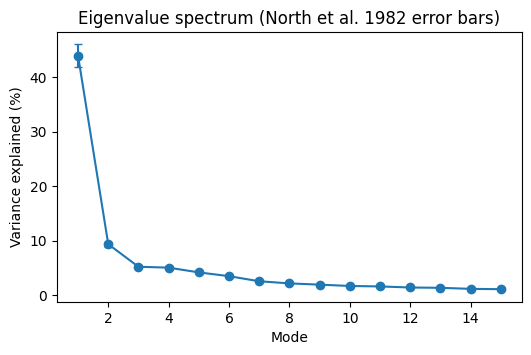

In [11]:
frac = eigvals / eigvals.sum()
print('Sum of eigenvalues = trace(COV)?', np.isclose(eigvals.sum(), np.trace(COV)))
for k in range(NMODES):
    print(f'EOF-{k+1}: {frac[k]*100:5.1f} %   (cumulative {frac[:k+1].sum()*100:5.1f} %)')

nshow = 15
err = frac[:nshow] * np.sqrt(2 / n)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(np.arange(1, nshow + 1), frac[:nshow] * 100, yerr=err * 100, fmt='o-', capsize=3)
ax.set_xlabel('Mode'); ax.set_ylabel('Variance explained (%)')
ax.set_title('Eigenvalue spectrum (North et al. 1982 error bars)')
plt.show()

## Step 6. Principal components

Projecting the data onto the eigenvectors gives the PC time series, $\mathbf{T} = \mathbf{X}\mathbf{E}$. Two properties to check:
- the variance of PC-$k$ equals $\lambda_k$;
- PCs are **uncorrelated** with each other (EOFs are orthogonal in space, PCs are uncorrelated in time).

Var(PC_k): [321.44  68.59  38.26  37.1 ]
lambda_k : [321.44  68.59  38.26  37.1 ]
Correlation among PCs:
[[ 1.  0.  0. -0.]
 [ 0.  1.  0. -0.]
 [ 0.  0.  1.  0.]
 [-0. -0.  0.  1.]]


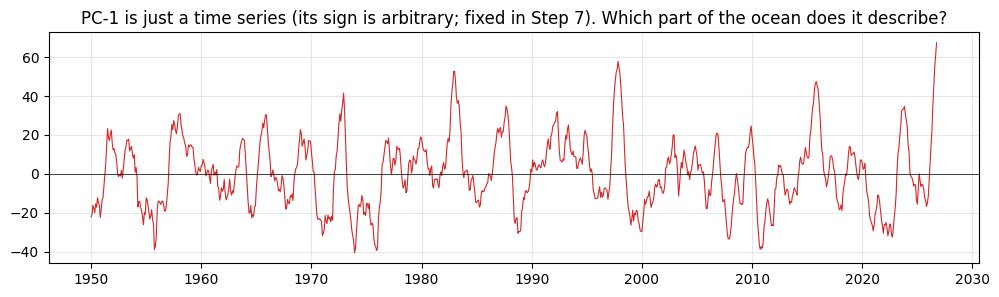

In [12]:
PCs = X @ eigvecs[:, :NMODES]     # (time, NMODES)

print('Var(PC_k):', np.round(PCs.var(axis=0, ddof=1), 2))
print('lambda_k :', np.round(eigvals[:NMODES], 2))
print('Correlation among PCs:')
print(np.round(np.corrcoef(PCs.T), 3))

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(anom.time, PCs[:, 0], color='tab:red', lw=0.8)
ax.axhline(0, color='k', lw=0.5); ax.grid(alpha=0.3)
ax.set_title('PC-1 is just a time series (its sign is arbitrary; fixed in Step 7). Which part of the ocean does it describe?')
plt.show()


## Step 7. Back to maps, and the sign convention

The eigenvector is a column of length $p$; we put it back into the (lat, lon) grid using `ocean_idx`.

**The sign of an EOF is arbitrary**: $(\mathbf{e}_k, u_k)$ and $(-\mathbf{e}_k, -u_k)$ describe the same pattern. We choose
- EOF-1 positive in the Niño 3.4 box (5°S–5°N, 170°W–120°W), so that **PC-1 > 0 means El Niño**;
- the other EOFs so that their largest-magnitude value is positive.

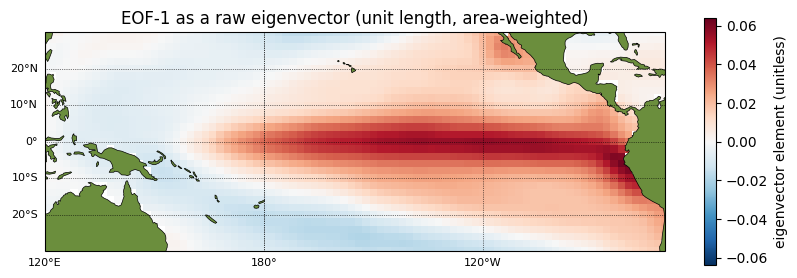

Length of EOF-1 vector: 0.9999997


In [13]:
def to_map(vec):
    # Put a length-p vector back on the (lat, lon) grid, with NaN over land
    out = np.full(ny * nx, np.nan)
    out[ocean_idx] = vec
    return out.reshape(ny, nx)

NINO34 = dict(lat=slice(5, -5), lon=slice(190, 240))

for k in range(NMODES):
    e_map = xr.DataArray(to_map(eigvecs[:, k]), dims=('lat', 'lon'), coords={'lat': anom.lat, 'lon': anom.lon})
    if k == 0:
        flip = e_map.sel(**NINO34).mean() < 0
    else:
        flip = eigvecs[np.argmax(np.abs(eigvecs[:, k])), k] < 0
    if flip:
        eigvecs[:, k] *= -1
        PCs[:, k] *= -1

eof_raw = xr.DataArray(np.stack([to_map(eigvecs[:, k]) for k in range(NMODES)]),
                       dims=('mode', 'lat', 'lon'),
                       coords={'mode': np.arange(1, NMODES + 1), 'lat': anom.lat, 'lon': anom.lon})

fig, ax = plt.subplots(figsize=(10, 4), subplot_kw={'projection': MAP_PROJ})
eof_raw.sel(mode=1).plot(ax=ax, transform=DATA_CRS, cmap='RdBu_r', center=0,
                         cbar_kwargs={'label': 'eigenvector element (unitless)', 'shrink': 0.8})
decorate_map(ax)
ax.set_title('EOF-1 as a raw eigenvector (unit length, area-weighted)')
plt.show()
print('Length of EOF-1 vector:', np.linalg.norm(eigvecs[:, 0]))

## Step 8. Where does SST move together with PC-1? Correlation maps

The raw eigenvector has unit length, so its values (~0.0x) depend on how many grid cells there are and have no physical meaning. A more intuitive question is:

> **At each grid cell, how strongly is the local SST anomaly correlated with PC-1?**

Mapping that correlation is how EOFs are usually presented (as in the lecture slides). For grid cell $j$ with anomaly $x_{t,j}$ and the PC $u_t$:

$$
r_j = \frac{\sum_{t}(x_{t,j}-\bar{x}_j)(u_t-\bar{u})}
           {\sqrt{\sum_{t}(x_{t,j}-\bar{x}_j)^2}\;\sqrt{\sum_{t}(u_t-\bar{u})^2}}
$$

We use the **unweighted** anomalies here: the weighting only affects how the modes are found, not how they are displayed.

### 8a. The loop way: one grid cell at a time

In [14]:
A = anom.values.reshape(nt, ny * nx)[:, ocean_idx]     # unweighted anomalies, (time, ocean cells)
u = PCs[:, 0]                                          # PC-1, (time,)

def corr_loop(A, u):
    r = np.empty(A.shape[1])
    for j in range(A.shape[1]):                         # loop over grid cells
        x = A[:, j]
        xd, ud = x - x.mean(), u - u.mean()             # deviations
        r[j] = np.sum(xd * ud) / np.sqrt(np.sum(xd**2) * np.sum(ud**2))
    return r

%time r_loop = corr_loop(A, u)
print(f'{len(r_loop)} correlations, range {r_loop.min():.2f} to {r_loop.max():.2f}')

CPU times: user 97.7 ms, sys: 899 μs, total: 98.6 ms
Wall time: 37.6 ms
2418 correlations, range -0.63 to 0.95


### 8b. The linear-algebra way: one matrix product

Look at the numerator: $\sum_t (x_{t,j}-\bar{x}_j)(u_t-\bar{u})$ is a **dot product** between two deviation vectors. Doing that for every column $j$ at once is just a matrix–vector product. If we first **standardize** every column (subtract the mean, divide by the standard deviation), the denominator disappears too:

$$
\mathbf{r} = \frac{1}{n-1}\,\mathbf{Z}_x^T\,\mathbf{z}_u
\qquad
\underbrace{(p \times 1)}_{\text{one } r \text{ per cell}} = \underbrace{(p \times n)}_{\mathbf{Z}_x^T}\;\underbrace{(n \times 1)}_{\mathbf{z}_u}
$$

where $\mathbf{Z}_x$ ($n \times p$) holds the standardized SST anomalies and $\mathbf{z}_u$ ($n$) the standardized PC. Three steps: (1) deviations, (2) divide by the standard deviation, (3) one matrix product.

This is the same structure as the covariance matrix $\mathbf{\Sigma} = \frac{1}{n-1}\mathbf{X}^T\mathbf{X}$ in Step 4; in fact $\frac{1}{n-1}\mathbf{Z}_x^T\mathbf{Z}_x$ is the **correlation matrix** of all grid cells.

CPU times: user 1.4 ms, sys: 162 μs, total: 1.56 ms
Wall time: 510 μs
Loop and matrix results identical? True


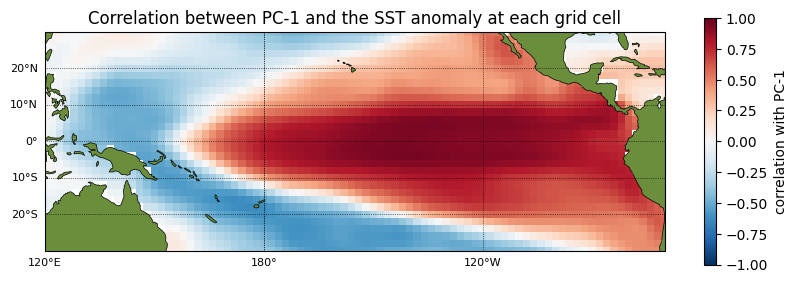

In [15]:
def standardize(M):
    Md = M - M.mean(axis=0)                  # 1) deviations from the time mean (each column)
    return Md / Md.std(axis=0, ddof=1)       # 2) divide by the standard deviation

Z_x = standardize(A)                         # (time, ocean cells)
z_u = standardize(u)                         # (time,)

%time r_vec = Z_x.T @ z_u / (n - 1)           # 3) one matrix-vector product
print('Loop and matrix results identical?', np.allclose(r_loop, r_vec))

fig, ax = plt.subplots(figsize=(10, 4), subplot_kw={'projection': MAP_PROJ})
xr.DataArray(to_map(r_vec), dims=('lat', 'lon'), coords={'lat': anom.lat, 'lon': anom.lon}).plot(
    ax=ax, transform=DATA_CRS, cmap='RdBu_r', vmin=-1, vmax=1,
    cbar_kwargs={'label': 'correlation with PC-1', 'shrink': 0.8})
decorate_map(ax)
ax.set_title('Correlation between PC-1 and the SST anomaly at each grid cell')
plt.show()

### 8c. All PCs at once, and regression maps

Replace the vector $\mathbf{z}_u$ by a matrix $\mathbf{Z}_U$ ($n \times k$) holding all $k$ standardized PCs. Then

$$
\mathbf{R} = \frac{1}{n-1}\,\mathbf{Z}_x^T\,\mathbf{Z}_U \qquad (p \times k)
$$

gives the correlation map of **every mode** in a single line. If we keep the SST deviations in °C instead of standardizing them, the same product gives a **regression map**: the SST change (°C) at each grid cell per one standard deviation of the PC, i.e., the amplitude of a typical event.

$$
\mathbf{B} = \frac{1}{n-1}\,\mathbf{X}_{dev}^T\,\mathbf{Z}_U \qquad (p \times k,\ \text{in °C})
$$

Max |difference| vs. xr.corr: 1.2516975402832031e-06


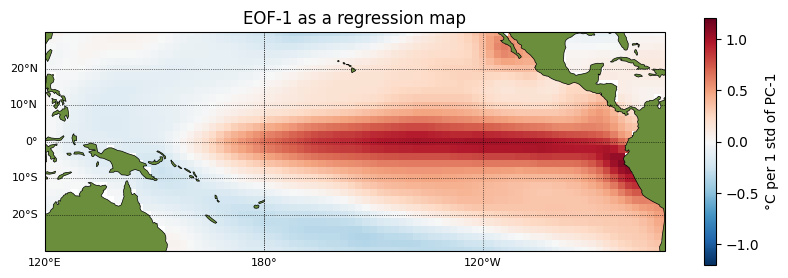

In [16]:
Z_U = standardize(PCs)                               # (time, NMODES)
R = Z_x.T @ Z_U / (n - 1)                            # (ocean cells, NMODES): correlation
B = (A - A.mean(axis=0)).T @ Z_U / (n - 1)           # (ocean cells, NMODES): °C per 1 std of PC

def to_maps(M):
    # Columns of a (p, k) matrix -> (mode, lat, lon) DataArray
    return xr.DataArray(np.stack([to_map(M[:, k]) for k in range(M.shape[1])]),
                        dims=('mode', 'lat', 'lon'),
                        coords={'mode': np.arange(1, M.shape[1] + 1), 'lat': anom.lat, 'lon': anom.lon})

eof_corr = to_maps(R)
eof_regr = to_maps(B)

# The same answer from xarray's built-in function
time = anom.time
pc_da = xr.DataArray(PCs, dims=('time', 'mode'), coords={'time': time, 'mode': np.arange(1, NMODES + 1)})
import warnings
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)          # land cells are all-NaN
    eof_corr_xr = xr.corr(pc_da, anom, dim='time')
print('Max |difference| vs. xr.corr:', float(np.abs(eof_corr - eof_corr_xr).max()))

fig, ax = plt.subplots(figsize=(10, 4), subplot_kw={'projection': MAP_PROJ})
eof_regr.sel(mode=1).plot(ax=ax, transform=DATA_CRS, cmap='RdBu_r', vmin=-1.2, vmax=1.2,
                          cbar_kwargs={'label': '°C per 1 std of PC-1', 'shrink': 0.8})
decorate_map(ax)
ax.set_title('EOF-1 as a regression map')
plt.show()

## Step 9. The EOF/PC figure

Left: EOF-$k$ (correlation map $\mathbf{R}$ from Step 8c). Right: PC-$k$ (unscaled, i.e., $\mathbf{T} = \mathbf{X}\mathbf{E}$, units of weighted °C).

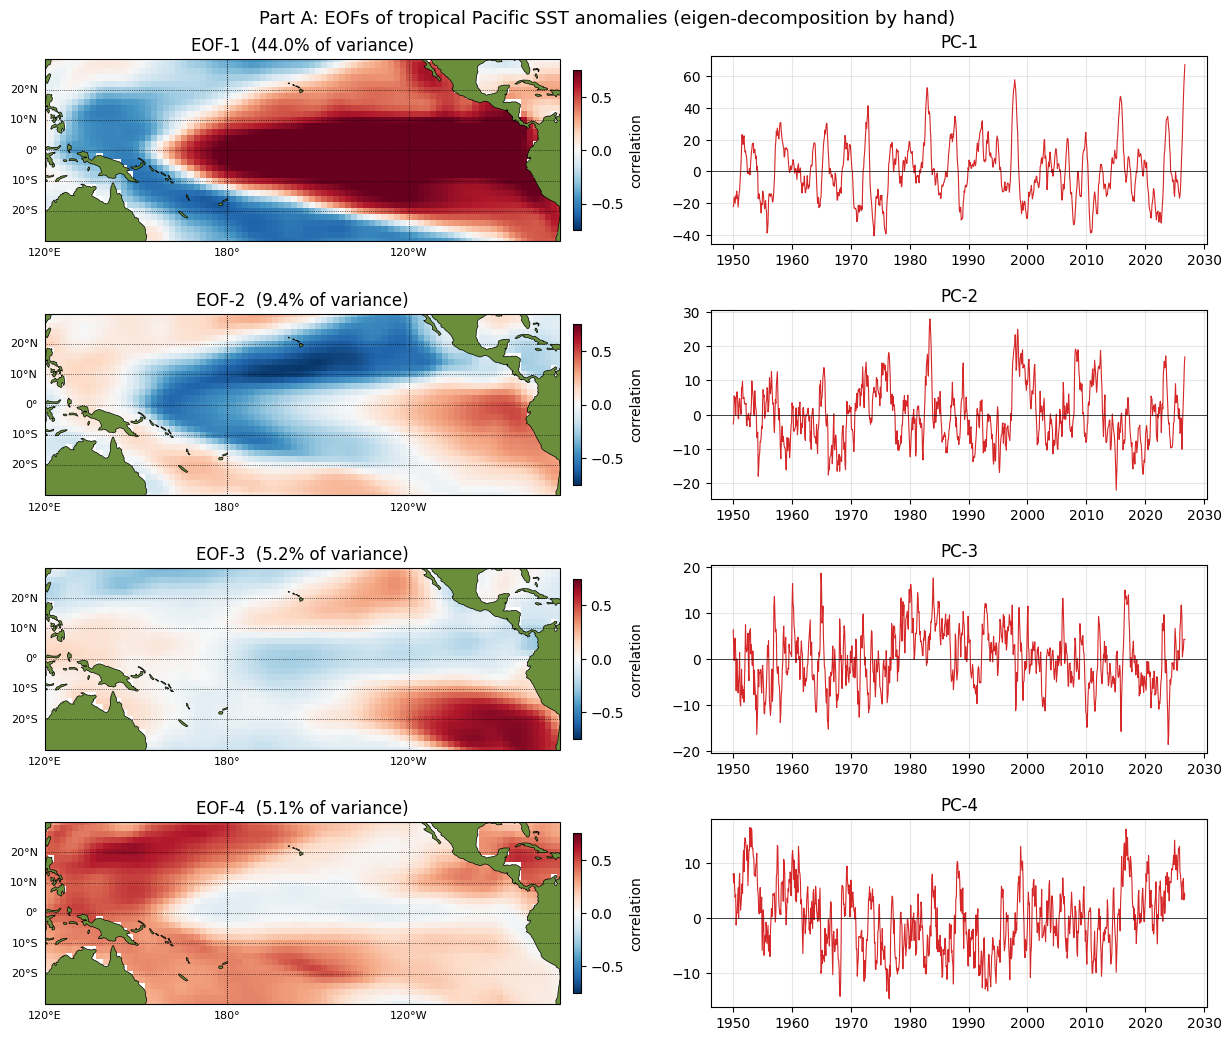

In [17]:
def plot_eof_pc(eof_maps, pcs, frac, suptitle='', vmax=0.75):
    nm = eof_maps.sizes['mode']
    fig = plt.figure(figsize=(15, 2.9 * nm))
    gs = fig.add_gridspec(nm, 2, width_ratios=[1.25, 1], wspace=0.08, hspace=0.35, top=0.93)
    for k in range(nm):
        ax = fig.add_subplot(gs[k, 0], projection=MAP_PROJ)
        im = eof_maps.isel(mode=k).plot(ax=ax, transform=DATA_CRS, cmap='RdBu_r',
                                        vmin=-vmax, vmax=vmax, add_colorbar=False)
        decorate_map(ax)
        ax.set_title(f'EOF-{k+1}  ({frac[k]*100:.1f}% of variance)')
        fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02, label='correlation')

        ax2 = fig.add_subplot(gs[k, 1])
        ax2.plot(pcs['time'], pcs.isel(mode=k), color='tab:red', lw=0.8)
        ax2.axhline(0, color='k', lw=0.5)
        ax2.set_title(f'PC-{k+1}')
        ax2.grid(alpha=0.3)
    fig.suptitle(suptitle, y=0.97, fontsize=13)
    plt.show()

plot_eof_pc(eof_corr, pc_da, frac, 'Part A: EOFs of tropical Pacific SST anomalies (eigen-decomposition by hand)')

### Side note: the SVD shortcut

Building a $p \times p$ covariance matrix becomes slow (and memory hungry) for large domains. The **singular value decomposition** of the data matrix itself, $\mathbf{X} = \mathbf{U}\mathbf{S}\mathbf{V}^T$, gives the same answer without ever forming $\mathbf{\Sigma}$:

$$
\mathbf{\Sigma} = \frac{1}{n-1}\mathbf{X}^T\mathbf{X} = \mathbf{V}\,\frac{\mathbf{S}^2}{n-1}\,\mathbf{V}^T
\;\;\Rightarrow\;\; \mathbf{E} = \mathbf{V},\quad \lambda_k = \frac{s_k^2}{n-1},\quad \mathbf{T} = \mathbf{U}\mathbf{S}
$$

This is what most EOF packages (including `eofs` in Part B) do internally.

In [18]:
%%time
U, s, Vt = np.linalg.svd(X, full_matrices=False)
eigvals_svd = s**2 / (n - 1)
print('Eigenvalues identical?        ', np.allclose(eigvals_svd[:NMODES], eigvals[:NMODES]))
print('|cos(angle)| between EOF vectors:', np.round(np.abs(np.sum(Vt[:NMODES].T * eigvecs[:, :NMODES], axis=0)), 6))

Eigenvalues identical?         True
|cos(angle)| between EOF vectors: [1. 1. 1. 1.]
CPU times: user 8.35 s, sys: 152 ms, total: 8.5 s
Wall time: 1.45 s


## Step 10. Reconstruction with a few modes

As in the 2-station example, the data can be approximately rebuilt from the first $k$ modes, $\mathbf{X} \approx \mathbf{T}_k\mathbf{E}_k^T$. Below we rebuild the field, undo the area weighting, and compare the **Niño 3.4 average** of the original and reconstructed anomalies. How many modes are needed to reproduce ENSO?

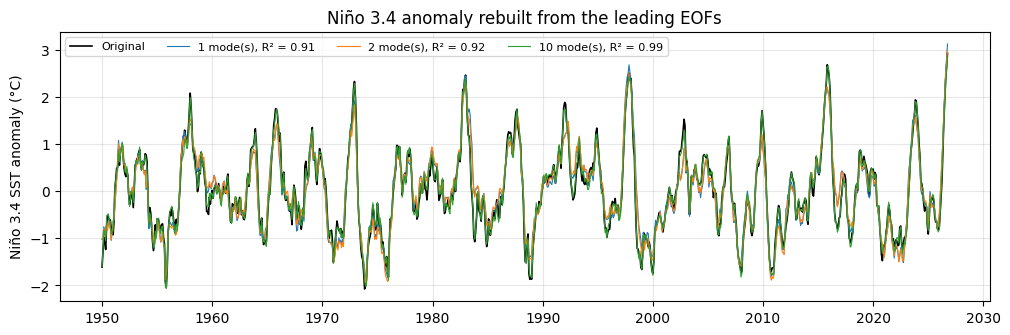

In [19]:
def reconstruct(k):
    # Reconstructed SST anomaly field (time, lat, lon) from the first k modes
    Ek = eigvecs[:, :k]
    Xk = (X @ Ek) @ Ek.T                  # T_k E_k^T
    field = np.full((nt, ny * nx), np.nan)
    field[:, ocean_idx] = Xk
    out = xr.DataArray(field.reshape(nt, ny, nx), dims=anom.dims, coords=anom.coords)
    return out / wgts                     # undo area weighting

nino_obs = anom.sel(**NINO34).mean(['lat', 'lon'])

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(time, nino_obs, color='k', lw=1.2, label='Original')
for k in [1, 2, 10]:
    nino_k = reconstruct(k).sel(**NINO34).mean(['lat', 'lon'])
    r2 = 1 - ((nino_obs - nino_k)**2).sum() / ((nino_obs - nino_obs.mean())**2).sum()
    ax.plot(time, nino_k, lw=0.8, label=f'{k} mode(s), R² = {float(r2):.2f}')
ax.set_ylabel('Niño 3.4 SST anomaly (°C)'); ax.legend(ncol=4, fontsize=8); ax.grid(alpha=0.3)
ax.set_title('Niño 3.4 anomaly rebuilt from the leading EOFs')
plt.show()

## Step 11. Is PC-1 ENSO?

Nobody told the EOF analysis where El Niño happens, yet EOF-1 picks out the equatorial eastern/central Pacific. Compare PC-1 (standardized) with the Niño 3.4 index computed from the same anomalies (as in `tutorial-sst-nino34.ipynb`).

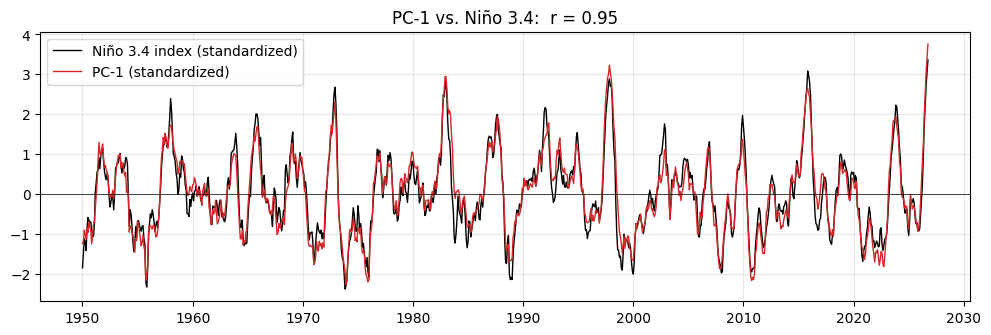

In [20]:
pc1_std = (pc_da.sel(mode=1) - pc_da.sel(mode=1).mean()) / pc_da.sel(mode=1).std()
nino_std = (nino_obs - nino_obs.mean()) / nino_obs.std()
r = float(xr.corr(pc1_std, nino_std))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(time, nino_std, color='k', lw=1, label='Niño 3.4 index (standardized)')
ax.plot(time, pc1_std, color='tab:red', lw=1, label='PC-1 (standardized)')
ax.axhline(0, color='k', lw=0.5)
ax.set_title(f'PC-1 vs. Niño 3.4:  r = {r:.2f}')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

# Part B. EOF analysis with the `eofs` package

In practice we rarely code the decomposition ourselves. The [`eofs`](https://ajdawson.github.io/eofs/) package (Dawson, 2016) works directly on `xarray` objects and handles the reshaping, land masking, centering and weighting for us:

| Part A (by hand) | `eofs` |
|---|---|
| reshape, drop NaN, center | `Eof(anom, weights=...)` |
| `eigvals`, `frac` | `solver.eigenvalues()`, `solver.varianceFraction()` |
| `eigvecs` → maps | `solver.eofs()` |
| `PCs = X @ E` | `solver.pcs(pcscaling=0)` |
| correlation maps | `solver.eofsAsCorrelation()` |
| North et al. error | `solver.northTest()` |

Note that `eofs` needs the weights on the spatial grid `(lat, lon)`, not only along `lat`; `wgts[:, np.newaxis]` broadcasts them over longitude.

In [21]:
from eofs.xarray import Eof

solver = Eof(anom, weights=wgts.values[:, np.newaxis])   # anom: unweighted anomalies (time, lat, lon)

eof_corr_pkg = solver.eofsAsCorrelation(neofs=NMODES)    # (mode, lat, lon)
pcs_pkg = solver.pcs(npcs=NMODES, pcscaling=0)           # (time, mode), unscaled
frac_pkg = solver.varianceFraction(neigs=NMODES)
north_err = solver.northTest(neigs=NMODES, vfscaled=True)

for k in range(NMODES):
    print(f'EOF-{k+1}: {float(frac_pkg[k])*100:5.1f} % ± {float(north_err[k])*100:.1f} %')

EOF-1:  44.0 % ± 2.0 %
EOF-2:   9.4 % ± 0.4 %
EOF-3:   5.2 % ± 0.2 %
EOF-4:   5.1 % ± 0.2 %


### Do Part A and Part B agree?

Signs are again arbitrary, so we align each package mode to the hand-computed one before comparing.

In [22]:
pcs_pkg = pcs_pkg.assign_coords(mode=np.arange(1, NMODES + 1))
eof_corr_pkg = eof_corr_pkg.assign_coords(mode=np.arange(1, NMODES + 1))

sign = np.sign([np.corrcoef(PCs[:, k], pcs_pkg.isel(mode=k))[0, 1] for k in range(NMODES)])
sign = xr.DataArray(sign, dims='mode', coords={'mode': pcs_pkg.mode})
pcs_pkg, eof_corr_pkg = pcs_pkg * sign, eof_corr_pkg * sign

print('Variance fractions identical?  ', np.allclose(frac_pkg.values, frac[:NMODES]))
print('Max |PC difference|:           ', float(np.abs(pcs_pkg.values - PCs).max()))
print('Max |EOF correlation difference|:', float(np.abs(eof_corr_pkg - eof_corr).max()))

Variance fractions identical?   True
Max |PC difference|:            3.147125244140625e-05
Max |EOF correlation difference|: 1.3113021850585938e-06


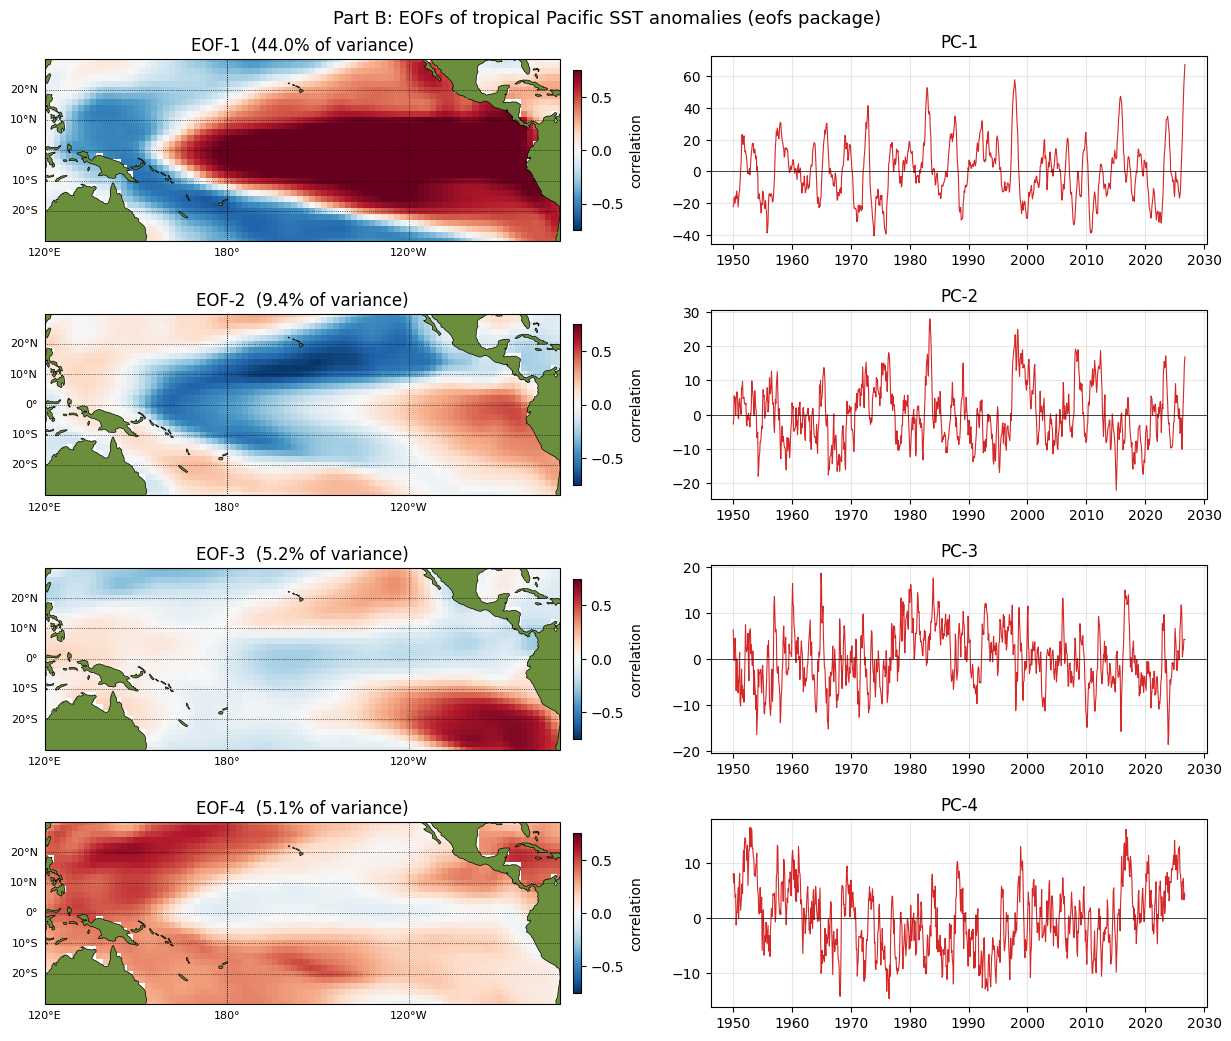

In [23]:
plot_eof_pc(eof_corr_pkg, pcs_pkg, frac_pkg.values, 'Part B: EOFs of tropical Pacific SST anomalies (eofs package)')

# Discussion and exercises

1. **Interpretation.** EOF-1 / PC-1 is ENSO. What do EOF-2 and PC-2 look like? (Hint: compare the 1997/98 and 2015/16 El Niños with 2002/03 and 2009/10, and read about "eastern-Pacific vs. central-Pacific" El Niño. Also check whether PC-2 looks like a slow, decadal signal.)
2. **Detrending.** Set `DETREND = False` and rerun. Which EOF changes most, and why?
3. **Weighting.** Rerun without area weighting (`wgts = 1`). For this domain, does it matter? Would it matter for a 60°S–60°N domain?
4. **Domain.** Extend the domain to the whole tropics (30°S–30°N, 0–360°). How much variance does EOF-1 explain now, and why is it lower? (Use the SVD route; the covariance matrix becomes large.)
5. **Caution.** EOFs are *statistical* modes forced to be orthogonal in space and uncorrelated in time; real physical modes need not be. Using the North et al. error bars, which of the leading EOFs are well separated? (See also Dommenget & Latif, 2002, *J. Climate*.)
6. **Correlation map of an index.** Using `standardize` and one matrix product (Step 8b), compute the correlation map between the Niño 3.4 index (`nino_obs`, Step 10) and SST. How similar is it to EOF-1? Then do the same for the Niño 1+2 index (10°S–0°, 90°W–80°W). Which EOF does it resemble?

**References**
- North, G. R., Bell, T. L., Cahalan, R. F., & Moeng, F. J. (1982). Sampling errors in the estimation of empirical orthogonal functions. *Monthly Weather Review*, 110, 699–706.
- Dommenget, D., & Latif, M. (2002). A cautionary note on the interpretation of EOFs. *Journal of Climate*, 15, 216–225.
- Dawson, A. (2016). eofs: A library for EOF analysis of meteorological, oceanographic, and climate data. *Journal of Open Research Software*, 4(1).
- Wilks, D. S. *Statistical Methods in the Atmospheric Sciences*, Chapter on Principal Component (EOF) Analysis.